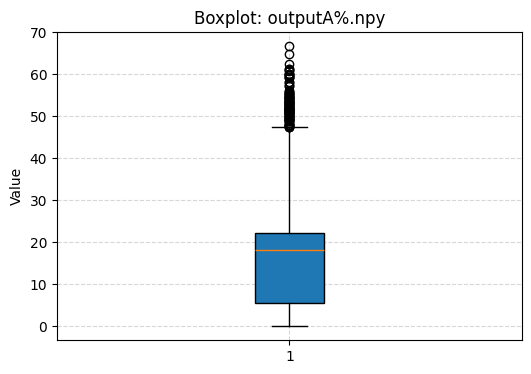

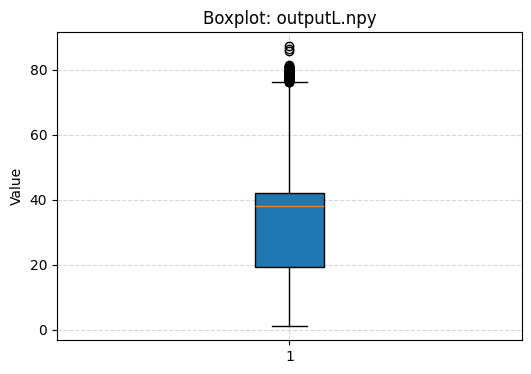

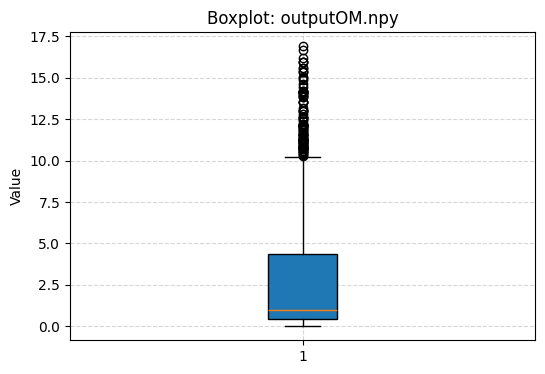

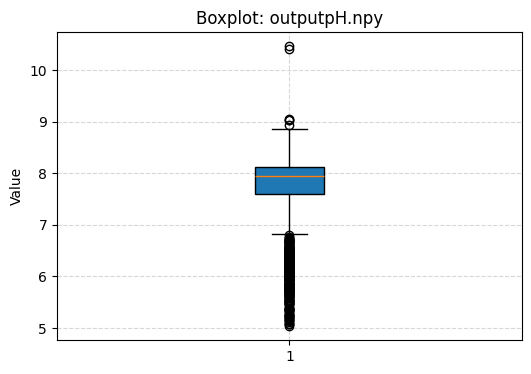

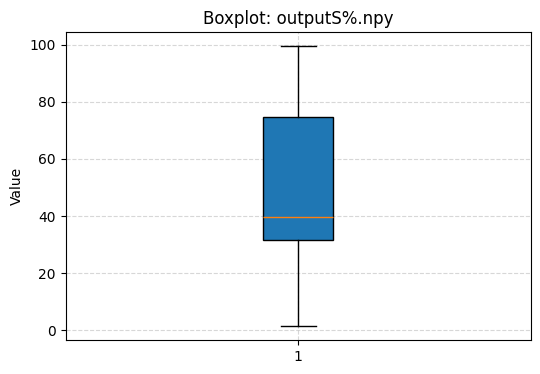

           file    shape       min        max     median       mean        std
0  outputA%.npy  (2156,)  0.000000  66.667831  18.218893  17.561063  13.368695
1   outputL.npy  (2156,)  1.092738  87.223606  38.133132  34.941673  17.005804
2  outputOM.npy  (2156,)  0.000000  16.892958   0.985607   2.787456   3.408665
3  outputpH.npy  (2156,)  5.034366  10.461000   7.944432   7.650052   0.780186
4  outputS%.npy  (2156,)  1.388695  99.413785  39.487934  46.918607  24.661866


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ---- Folder containing .npy files ----
folder_path = "./unitask_data/output/"  

# ---- Prepare dataframe for statistics ----
stats_list = []

# ---- Loop through all .npy files ----
for file_name in os.listdir(folder_path):
    if file_name.endswith(".npy"):
        file_path = os.path.join(folder_path, file_name)
        data = np.load(file_path).flatten()  # shape (N,1) -> flatten to (N,)
        
        stats = {
            "file": file_name,
            "shape": data.shape,
            "min": np.min(data),
            "max": np.max(data),
            "median": np.median(data),
            "mean": np.mean(data),
            "std": np.std(data)
        }
        stats_list.append(stats)
        
        # ---- Boxplot ----
        plt.figure(figsize=(6, 4))
        plt.boxplot(data, vert=True, patch_artist=True)
        plt.title(f"Boxplot: {file_name}")
        plt.ylabel("Value")
        plt.grid(True, linestyle="--", alpha=0.5)
        plt.show()

# ---- Combine stats into a DataFrame ----
stats_df = pd.DataFrame(stats_list)
print(stats_df)


In [3]:
inputs = np.load("inputs.npy")
print("shape: ", inputs.shape)
print("Max of landuse: ", np.max(inputs[:, :, :,6]))
print("Min of landuse: ", np.min(inputs[:, :, :,6]))

shape:  (2156, 7, 7, 38)
Max of landuse:  210.0
Min of landuse:  0.0


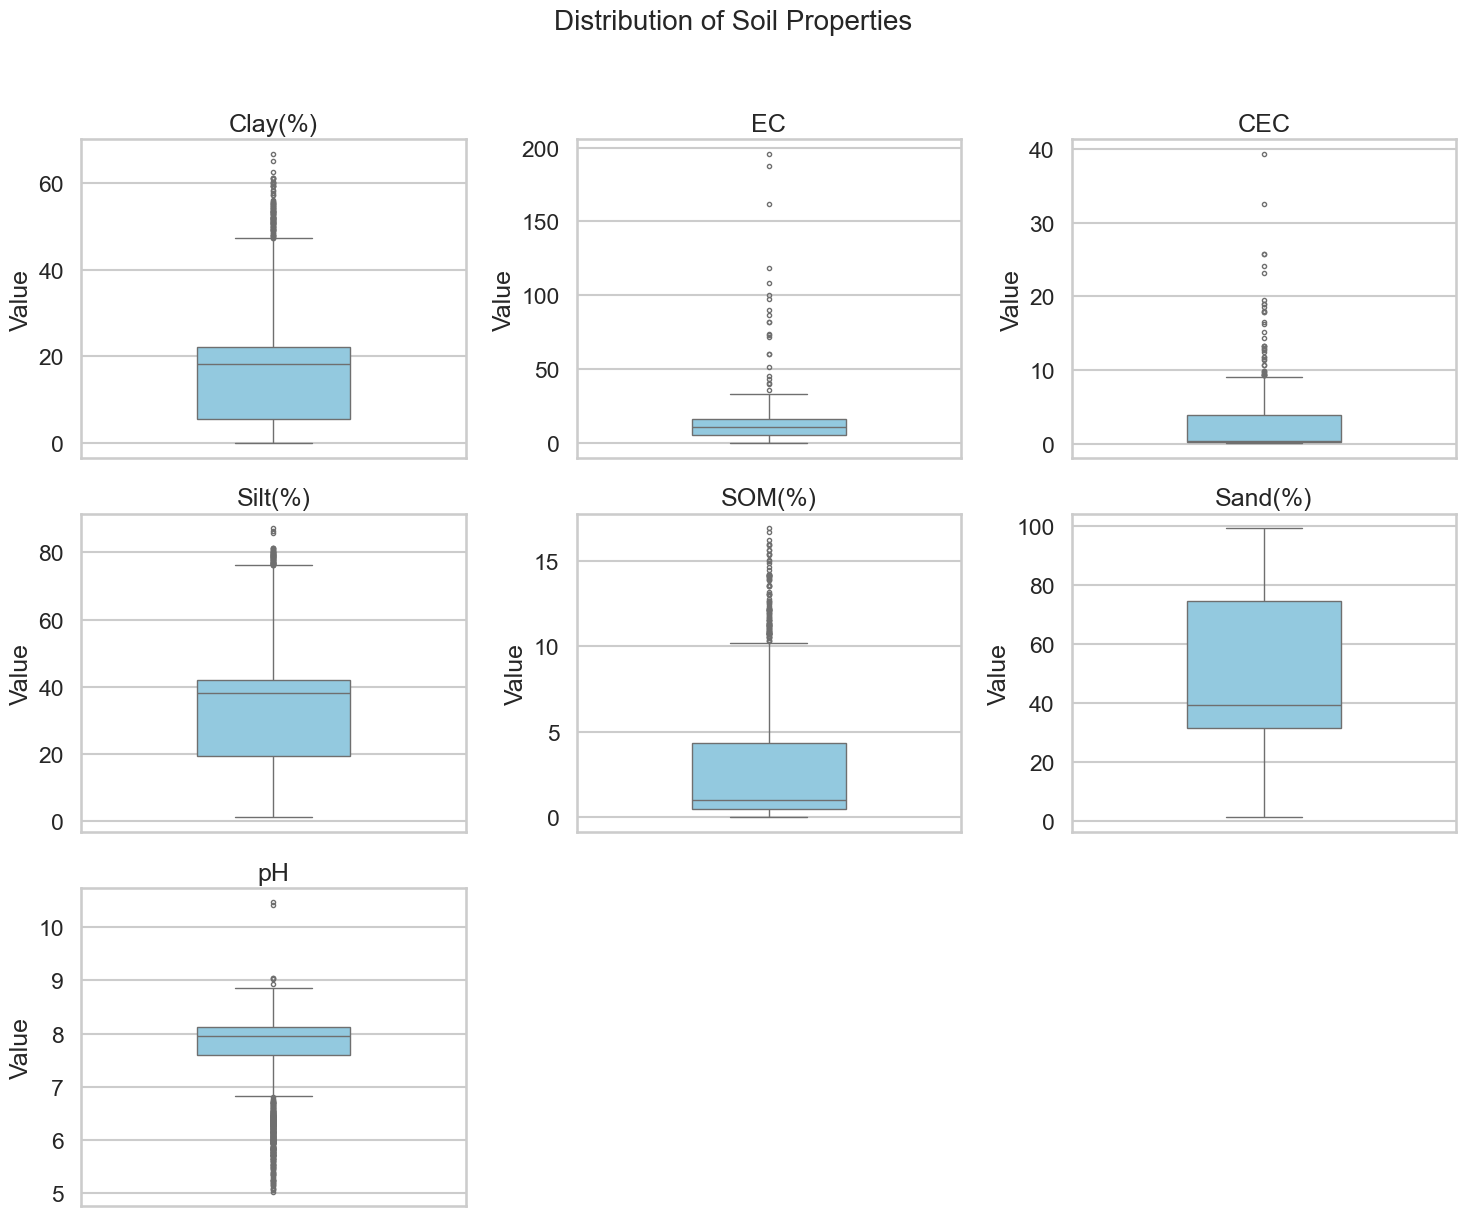

            file     min       max   median     mean      std
0   outputA%.npy  0.0000   66.6678  18.2189  17.5611  13.3687
1   outputCE.npy  0.0630  195.6835  11.2587  12.2516  11.0571
2  outputCEC.npy  0.0637   39.3191   0.3601   1.7814   2.7809
3    outputL.npy  1.0927   87.2236  38.1331  34.9417  17.0058
4   outputOM.npy  0.0000   16.8930   0.9856   2.7875   3.4087
5   outputS%.npy  1.3887   99.4138  39.4879  46.9186  24.6619
6   outputpH.npy  5.0344   10.4610   7.9444   7.6501   0.7802


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

# -------------------- Config --------------------
folder_path = "./unitask_data/output/"  # change if needed

# Mapping between filename and plot title
TITLE_MAP = {
    "outputA%.npy": "Clay(%)",
    "outputS%.npy": "Sand(%)",
    "outputL.npy": "Silt(%)",
    "outputpH.npy": "pH",
    "outputCE.npy": "EC",
    "outputCEC.npy": "CEC",
    "outputOM.npy": "SOM(%)",

}

sns.set_theme(style="whitegrid", context="talk")

# -------------------- Load data & stats --------------------
stats_list = []
data_dict = {}

for file_name in sorted(os.listdir(folder_path)):
    if file_name.endswith(".npy"):
        file_path = os.path.join(folder_path, file_name)
        data = np.load(file_path).flatten()

        data_dict[file_name] = data

        stats_list.append({
            "file": file_name,
            "min": np.min(data),
            "max": np.max(data),
            "median": np.median(data),
            "mean": np.mean(data),
            "std": np.std(data)
        })

stats_df = pd.DataFrame(stats_list)

# -------------------- Plotting --------------------
n_files = len(data_dict)
n_cols = 3
n_rows = math.ceil(n_files / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, (file_name, data) in zip(axes, data_dict.items()):
    title = TITLE_MAP.get(file_name, file_name.replace(".npy", "").title())

    sns.boxplot(
        y=data,
        ax=ax,
        color="skyblue",
        width=0.4,
        fliersize=3
    )

    ax.set_title(title)
    ax.set_ylabel("Value")
    ax.set_xlabel("")
    
# Remove unused subplots
for ax in axes[len(data_dict):]:
    ax.remove()

fig.suptitle("Distribution of Soil Properties", fontsize=20, y=1.02)
plt.tight_layout()
plt.show()

# -------------------- Stats Output --------------------
print(stats_df.round(4))


# stats by depth 

# before imputation 

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd


# ============================================================
# 1. CONFIGURATION
# ============================================================

# Directory containing files such as:
# pH_spline_result.csv
# SOM_spline_result.csv
# CEC_spline_result.csv
# EC_spline_result.csv
DATA_DIR = Path(r"SixDepths")

# Output directory

OUTPUT_DIR = Path("dataset_statistics")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Input file pattern
FILE_PATTERN = "*_spline_result.csv"

# Expected columns
REQUIRED_COLUMNS = ["SID", "UD", "LD", "SPLINED_VALUE"]


# ============================================================
# 2. LOAD AND PROCESS ALL PROPERTY FILES
# ============================================================

all_data = []
statistics_results = []
count_results = []

files = sorted(DATA_DIR.glob(FILE_PATTERN))

if not files:
    raise FileNotFoundError(
        f"No files matching '{FILE_PATTERN}' were found in {DATA_DIR}"
    )

print(f"Found {len(files)} property files.")

for file_path in files:

    # Extract property name from filename
    # Example: pH_spline_result.csv -> pH
    property_name = file_path.name.replace(
        "_spline_result.csv", ""
    )

    print(f"Processing property: {property_name}")

    # Read file
    df = pd.read_csv(file_path)

    # Check required columns
    missing_columns = [
        col for col in REQUIRED_COLUMNS
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{file_path.name} is missing columns: {missing_columns}"
        )

    # Keep only the relevant columns
    df = df[REQUIRED_COLUMNS].copy()

    # Convert numerical columns to numeric values
    df["UD"] = pd.to_numeric(df["UD"], errors="coerce")
    df["LD"] = pd.to_numeric(df["LD"], errors="coerce")
    df["SPLINED_VALUE"] = pd.to_numeric(
        df["SPLINED_VALUE"], errors="coerce"
    )

    # Identify the soil property
    df["property"] = property_name

    # Create a readable depth-interval label
    # Example: UD=0, LD=5 -> 0-5 cm
    def format_depth(row):
        ud = row["UD"]
        ld = row["LD"]

        if pd.isna(ud) or pd.isna(ld):
            return "Unknown depth"

        return f"{ud:g}-{ld:g} cm"

    df["depth_interval"] = df.apply(format_depth, axis=1)

    # Store the data for combined outputs
    all_data.append(df)

    # --------------------------------------------------------
    # 3. DESCRIPTIVE STATISTICS BY DEPTH
    # --------------------------------------------------------

    for (ud, ld, depth), group in df.groupby(
        ["UD", "LD", "depth_interval"],
        dropna=False
    ):

        values = group["SPLINED_VALUE"]

        # Non-missing values used for numerical statistics
        valid_values = values.dropna()

        # Number of records and number of unique profiles
        n_records = len(group)
        n_profiles = group["SID"].nunique(dropna=True)

        # Missing-value statistics
        n_missing = int(values.isna().sum())
        n_valid = int(values.notna().sum())

        missing_percentage = (
            100 * n_missing / n_records
            if n_records > 0 else np.nan
        )

        # Descriptive statistics
        stats = {
            "property": property_name,
            "UD": ud,
            "LD": ld,
            "depth_interval": depth,
            "N_records": n_records,
            "N_unique_profiles": n_profiles,
            "N_non_missing": n_valid,
            "N_missing": n_missing,
            "missing_percentage": missing_percentage,
            "mean": valid_values.mean(),
            "std": valid_values.std(),
            "min": valid_values.min(),
            "Q1": valid_values.quantile(0.25),
            "median": valid_values.median(),
            "Q3": valid_values.quantile(0.75),
            "max": valid_values.max(),
        }

        statistics_results.append(stats)

        # ----------------------------------------------------
        # 4. OBSERVATION COUNTS BY PROPERTY AND DEPTH
        # ----------------------------------------------------

        count_results.append({
            "property": property_name,
            "UD": ud,
            "LD": ld,
            "depth_interval": depth,
            "N_records": n_records,
            "N_unique_profiles": n_profiles,
            "N_non_missing": n_valid,
            "N_missing": n_missing,
            "missing_percentage": missing_percentage,
        })


# ============================================================
# 5. COMBINE RESULTS
# ============================================================

combined_data = pd.concat(all_data, ignore_index=True)

stats_df = pd.DataFrame(statistics_results)
counts_df = pd.DataFrame(count_results)

# Sort by property and depth
stats_df = stats_df.sort_values(
    ["property", "UD", "LD"],
    na_position="last"
).reset_index(drop=True)

counts_df = counts_df.sort_values(
    ["property", "UD", "LD"],
    na_position="last"
).reset_index(drop=True)


# ============================================================
# 6. CREATE A WIDE TABLE OF OBSERVATION COUNTS
# ============================================================

# Each row is a depth interval, each column a soil property.
# Values represent the number of records before missing-value handling.

counts_wide = counts_df.pivot_table(
    index=["UD", "LD", "depth_interval"],
    columns="property",
    values="N_records",
    aggfunc="first"
).reset_index()

counts_wide.columns.name = None


# Create a second wide table for non-missing values
valid_counts_wide = counts_df.pivot_table(
    index=["UD", "LD", "depth_interval"],
    columns="property",
    values="N_non_missing",
    aggfunc="first"
).reset_index()

valid_counts_wide.columns.name = None


# ============================================================
# 7. EXPORT RESULTS
# ============================================================

# Full descriptive statistics
stats_csv = OUTPUT_DIR / "descriptive_statistics_by_property_depth_before_imputation.csv"
stats_df.to_csv(stats_csv, index=False)

# Counts in long format
counts_csv = OUTPUT_DIR / "observation_counts_by_property_depth_before_imputation.csv"
counts_df.to_csv(counts_csv, index=False)

# Counts in wide format
counts_wide_csv = OUTPUT_DIR / "observation_counts_wide_before_imputation.csv"
counts_wide.to_csv(counts_wide_csv, index=False)

# Non-missing counts in wide format
valid_counts_csv = OUTPUT_DIR / "non_missing_counts_wide_before_imputation.csv"
valid_counts_wide.to_csv(valid_counts_csv, index=False)

# Combined workbook
excel_path = OUTPUT_DIR / "spline_descriptive_statistics_before_imputation.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:

    stats_df.to_excel(
        writer,
        sheet_name="Descriptive statistics",
        index=False
    )

    counts_df.to_excel(
        writer,
        sheet_name="Counts long",
        index=False
    )

    counts_wide.to_excel(
        writer,
        sheet_name="Counts by depth",
        index=False
    )

    valid_counts_wide.to_excel(
        writer,
        sheet_name="Non-missing counts",
        index=False
    )

    combined_data.to_excel(
        writer,
        sheet_name="Combined raw data",
        index=False
    )


# ============================================================
# 8. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 70)
print("DESCRIPTIVE STATISTICS BY PROPERTY AND DEPTH")
print("=" * 70)

print(stats_df.round(3).to_string(index=False))

print("\n" + "=" * 70)
print("OBSERVATION COUNTS BY DEPTH")
print("=" * 70)

print(counts_wide.to_string(index=False))

print("\nFiles saved in:")
print(OUTPUT_DIR)

print("\nGenerated files:")
print(f"- {stats_csv.name}")
print(f"- {counts_csv.name}")
print(f"- {counts_wide_csv.name}")
print(f"- {valid_counts_csv.name}")
print(f"- {excel_path.name}")

Found 7 property files.
Processing property: A%
Processing property: CE
Processing property: CEC
Processing property: L%
Processing property: OM%
Processing property: pH
Processing property: S%

DESCRIPTIVE STATISTICS BY PROPERTY AND DEPTH
property  UD  LD depth_interval  N_records  N_unique_profiles  N_non_missing  N_missing  missing_percentage   mean    std   min     Q1  median     Q3     max
      A%   0   5         0-5 cm       2020               2020           2020          0                 0.0 15.031 14.162 0.000  3.977  11.550 19.091  67.500
      A%   5  15        5-15 cm       2021               2021           2021          0                 0.0 15.170 14.110 0.000  4.100  11.790 19.156  67.500
      A%  15  30       15-30 cm       1965               1965           1965          0                 0.0 15.704 14.403 0.000  4.100  12.240 20.192  67.500
      A%  30  60       30-60 cm       1485               1485           1485          0                 0.0 16.630 15.157 0.000 

In [7]:
from pathlib import Path

import numpy as np
import pandas as pd


# ============================================================
# 1. CONFIGURATION
# ============================================================

DATA_DIR = Path(r"SixDepths")

OUTPUT_DIR = DATA_DIR / "outlier_handling"
CLEAN_DIR = OUTPUT_DIR / "adjusted_data"

CLEAN_DIR.mkdir(parents=True, exist_ok=True)

IQR_MULTIPLIER = 1.5

FILE_PATTERN = "*_spline_result.csv"

REQUIRED_COLUMNS = ["SID", "UD", "LD", "SPLINED_VALUE"]

# Adapt these names to the property names in your files.
# These properties are expressed as percentages.
PERCENTAGE_PROPERTIES = {
    "Clay", "Clay_pct",
    "Silt", "Silt_pct",
    "Sand", "Sand_pct",
    "A", "A%", "Clay_content",
    "L", "L%", "Silt_content",
    "S", "S%", "Sand_content"
}


# ============================================================
# 2. HANDLE OUTLIERS BY DEPTH USING WINSORIZATION
# ============================================================

def handle_outliers_by_depth(
    df,
    property_name,
    iqr_multiplier=1.5,
    is_percentage=False
):
    """
    Handle outliers independently for each depth interval.

    Method:
      1. Calculate IQR bounds separately at each depth.
      2. Cap values outside these bounds instead of removing them.
      3. For percentage properties, additionally constrain values
         to [0, 100].

    Original records and missing values are preserved.

    Returns:
      adjusted_df: data with adjusted SPLINED_VALUE
      report_df: outlier-handling statistics by depth
    """

    adjusted_df = df.copy()

    adjusted_df["UD"] = pd.to_numeric(
        adjusted_df["UD"], errors="coerce"
    )
    adjusted_df["LD"] = pd.to_numeric(
        adjusted_df["LD"], errors="coerce"
    )
    adjusted_df["SPLINED_VALUE"] = pd.to_numeric(
        adjusted_df["SPLINED_VALUE"], errors="coerce"
    )

    original_values = adjusted_df["SPLINED_VALUE"].copy()

    report = []

    for (ud, ld), group in adjusted_df.groupby(
        ["UD", "LD"], dropna=False, sort=True
    ):

        values = group["SPLINED_VALUE"]
        valid = values.dropna()

        n_records = len(group)
        n_valid = len(valid)
        n_missing = int(values.isna().sum())

        if n_valid == 0:
            report.append({
                "property": property_name,
                "UD": ud,
                "LD": ld,
                "N_records": n_records,
                "N_valid": 0,
                "N_missing": n_missing,
                "N_IQR_outliers": 0,
                "N_adjusted_IQR": 0,
                "N_adjusted_percentage_bounds": 0,
                "N_adjusted_total": 0,
                "lower_IQR": np.nan,
                "upper_IQR": np.nan,
                "min_before": np.nan,
                "max_before": np.nan,
                "min_after": np.nan,
                "max_after": np.nan
            })
            continue

        # Calculate IQR bounds from the original valid values
        q1 = valid.quantile(0.25)
        q3 = valid.quantile(0.75)
        iqr = q3 - q1

        lower_iqr = q1 - iqr_multiplier * iqr
        upper_iqr = q3 + iqr_multiplier * iqr

        # Detect outliers before adjustment
        iqr_outlier_mask = (
            values.notna()
            & (
                (values < lower_iqr)
                | (values > upper_iqr)
            )
        )

        # Winsorize: cap outliers instead of removing them
        adjusted_values = values.clip(
            lower=lower_iqr,
            upper=upper_iqr
        )

        # Apply physical constraints for percentage properties
        percentage_adjusted_mask = pd.Series(
            False, index=group.index
        )

        if is_percentage:
            before_percentage_clip = adjusted_values.copy()

            adjusted_values = adjusted_values.clip(
                lower=0,
                upper=100
            )

            percentage_adjusted_mask = (
                adjusted_values.ne(before_percentage_clip)
                & adjusted_values.notna()
            )

        # Save adjusted values at their original indices
        adjusted_df.loc[
            group.index, "SPLINED_VALUE"
        ] = adjusted_values

        # Values modified by either operation
        total_adjusted_mask = (
            adjusted_values.notna()
            & adjusted_values.ne(values)
        )

        n_iqr_outliers = int(iqr_outlier_mask.sum())
        n_adjusted_iqr = int(
            (
                iqr_outlier_mask
                & adjusted_values.ne(values)
            ).sum()
        )
        n_adjusted_percentage = int(
            percentage_adjusted_mask.sum()
        )
        n_adjusted_total = int(total_adjusted_mask.sum())

        report.append({
            "property": property_name,
            "UD": ud,
            "LD": ld,
            "N_records": n_records,
            "N_valid": n_valid,
            "N_missing": n_missing,
            "N_IQR_outliers": n_iqr_outliers,
            "N_adjusted_IQR": n_adjusted_iqr,
            "N_adjusted_percentage_bounds": n_adjusted_percentage,
            "N_adjusted_total": n_adjusted_total,
            "lower_IQR": lower_iqr,
            "upper_IQR": upper_iqr,
            "min_before": valid.min(),
            "max_before": valid.max(),
            "min_after": adjusted_values.min(),
            "max_after": adjusted_values.max()
        })

    # Confirm that records and missing values were preserved
    assert len(adjusted_df) == len(df)
    assert adjusted_df["SPLINED_VALUE"].isna().sum() == (
        original_values.isna().sum()
    )

    return adjusted_df, pd.DataFrame(report)


# ============================================================
# 3. PROCESS ALL PROPERTY FILES
# ============================================================

files = sorted(DATA_DIR.glob(FILE_PATTERN))

if not files:
    raise FileNotFoundError(
        f"No files matching {FILE_PATTERN} found in {DATA_DIR}"
    )

all_reports = []
all_adjusted_records = []
final_statistics = []

for file_path in files:

    property_name = file_path.name.replace(
        "_spline_result.csv", ""
    )

    print(f"\nProcessing: {property_name}")

    df = pd.read_csv(file_path)

    missing_columns = [
        col for col in REQUIRED_COLUMNS
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{file_path.name} is missing columns: "
            f"{missing_columns}"
        )

    df["SPLINED_VALUE"] = pd.to_numeric(
        df["SPLINED_VALUE"], errors="coerce"
    )

    # Match property names case-insensitively
    is_percentage = property_name.casefold() in {
        p.casefold() for p in PERCENTAGE_PROPERTIES
    }

    # Adjust outliers without deleting records
    adjusted_df, report_df = handle_outliers_by_depth(
        df=df,
        property_name=property_name,
        iqr_multiplier=IQR_MULTIPLIER,
        is_percentage=is_percentage
    )

    # Save adjusted property dataset
    adjusted_path = CLEAN_DIR / file_path.name
    adjusted_df.to_csv(adjusted_path, index=False)

    # Collect report
    all_reports.append(report_df)

    # Collect adjusted values for inspection
    adjusted_records = adjusted_df.copy()
    adjusted_records.insert(0, "property", property_name)
    all_adjusted_records.append(adjusted_records)

    # Calculate final statistics across all depths
    # Missing values are excluded from these calculations.
    values = adjusted_df["SPLINED_VALUE"].dropna()

    final_statistics.append({
        "property": property_name,
        "N_records": len(adjusted_df),
        "N_non_missing": len(values),
        "N_missing": int(
            adjusted_df["SPLINED_VALUE"].isna().sum()
        ),
        "mean": values.mean(),
        "std": values.std(),
        "min": values.min(),
        "q1": values.quantile(0.25),
        "median": values.median(),
        "q3": values.quantile(0.75),
        "max": values.max()
    })

    print(f"  Records preserved: {len(adjusted_df)}")
    print(f"  Values adjusted: {report_df['N_adjusted_total'].sum()}")


# ============================================================
# 4. COMBINE REPORTS
# ============================================================

report_df = pd.concat(all_reports, ignore_index=True)
adjusted_records_df = pd.concat(
    all_adjusted_records, ignore_index=True
)
statistics_df = pd.DataFrame(final_statistics)


# ============================================================
# 5. EXPORT RESULTS
# ============================================================

report_df.to_csv(
    OUTPUT_DIR / "outlier_handling_by_property_depth.csv",
    index=False
)

adjusted_records_df.to_csv(
    OUTPUT_DIR / "all_adjusted_property_values.csv",
    index=False
)

statistics_df.to_csv(
    OUTPUT_DIR / "property_statistics_after_adjustment.csv",
    index=False
)

with pd.ExcelWriter(
    OUTPUT_DIR / "outlier_handling_results.xlsx",
    engine="openpyxl"
) as writer:

    statistics_df.to_excel(
        writer, sheet_name="Final statistics", index=False
    )

    report_df.to_excel(
        writer, sheet_name="Adjustment by depth", index=False
    )

    adjusted_records_df.to_excel(
        writer, sheet_name="Adjusted records", index=False
    )


# ============================================================
# 6. DISPLAY RESULTS
# ============================================================

print("\nFINAL STATISTICS AFTER OUTLIER HANDLING")
print(
    statistics_df.round(3).to_string(index=False)
)

print("\nOUTLIER HANDLING SUMMARY")
print(
    report_df.groupby("property")[
        [
            "N_records",
            "N_IQR_outliers",
            "N_adjusted_total"
        ]
    ].sum().to_string()
)

print(f"\nResults saved in: {OUTPUT_DIR}")


Processing: A%
  Records preserved: 9050
  Values adjusted: 582

Processing: CE
  Records preserved: 8837
  Values adjusted: 1310

Processing: CEC
  Records preserved: 4938
  Values adjusted: 197

Processing: L%
  Records preserved: 9004
  Values adjusted: 103

Processing: OM%
  Records preserved: 1677
  Values adjusted: 131

Processing: pH
  Records preserved: 9164
  Values adjusted: 597

Processing: S%
  Records preserved: 9148
  Values adjusted: 12

FINAL STATISTICS AFTER OUTLIER HANDLING
property  N_records  N_non_missing  N_missing   mean    std   min     q1  median     q3     max
      A%       9050           9050          0 15.238 13.474 0.000  3.800  11.790 21.323  60.945
      CE       8837           8837          0  0.338  0.200 0.000  0.184   0.301  0.397   0.871
     CEC       4938           4938          0  9.385  8.275 0.000  3.477   5.264 13.525  30.001
      L%       9004           9004          0 34.812 18.856 0.000 17.565  37.400 44.070  84.589
     OM%       1677   

In [10]:
# ============================================================
# STATISTICS AFTER OUTLIER HANDLING, BY PROPERTY AND DEPTH
# ============================================================

adjusted_data = pd.concat(all_adjusted_records, ignore_index=True)

# Ensure numeric values
adjusted_data["UD"] = pd.to_numeric(
    adjusted_data["UD"], errors="coerce"
)
adjusted_data["LD"] = pd.to_numeric(
    adjusted_data["LD"], errors="coerce"
)
adjusted_data["SPLINED_VALUE"] = pd.to_numeric(
    adjusted_data["SPLINED_VALUE"], errors="coerce"
)

# Calculate statistics by property and depth
grouped = adjusted_data.groupby(
    ["property", "UD", "LD"],
    dropna=False,
    sort=True
)

stats_by_depth = grouped.agg(
    N_records=("SID", "size"),
    N_unique_profiles=("SID", "nunique"),
    mean=("SPLINED_VALUE", "mean"),
    std=("SPLINED_VALUE", "std"),
    min=("SPLINED_VALUE", "min"),
    median=("SPLINED_VALUE", "median"),
    max=("SPLINED_VALUE", "max")
).reset_index()

# Calculate quartiles separately
quartiles = grouped["SPLINED_VALUE"].quantile(
    [0.25, 0.75]
).unstack()

quartiles.columns = ["Q1", "Q3"]
quartiles = quartiles.reset_index()

stats_by_depth = stats_by_depth.merge(
    quartiles,
    on=["property", "UD", "LD"],
    how="left"
)

# Create depth interval labels
stats_by_depth["depth_interval"] = stats_by_depth.apply(
    lambda row: (
        f"{row['UD']:g}-{row['LD']:g} cm"
        if pd.notna(row["UD"]) and pd.notna(row["LD"])
        else "Unknown depth"
    ),
    axis=1
)

# Arrange the columns exactly as requested
stats_by_depth = stats_by_depth[
    [
        "property",
        "UD",
        "LD",
        "depth_interval",
        "N_records",
        "N_unique_profiles",
        "mean",
        "std",
        "min",
        "Q1",
        "median",
        "Q3",
        "max"
    ]
]

stats_by_depth = stats_by_depth.sort_values(
    ["property", "UD", "LD"],
    na_position="last"
).reset_index(drop=True)

# Export CSV
output_path = (
    OUTPUT_DIR
    / "descriptive_statistics_after_outlier_handling_by_depth.csv"
)

stats_by_depth.to_csv(
    output_path,
    index=False,
    float_format="%.4f"
)

print(stats_by_depth.to_string(index=False))
print(f"\nCSV saved to: {output_path}")

property  UD  LD depth_interval  N_records  N_unique_profiles      mean       std      min        Q1    median        Q3        max
      A%   0   5         0-5 cm       2020               2020 14.225800 12.082288 0.000000  3.976987 11.550000 19.090711  41.761296
      A%   5  15        5-15 cm       2021               2021 14.366223 12.037002 0.000000  4.100000 11.790000 19.155733  41.739333
      A%  15  30       15-30 cm       1965               1965 15.058665 12.740594 0.000000  4.100000 12.240000 20.192036  44.330091
      A%  30  60       30-60 cm       1485               1485 16.390225 14.493560 0.000000  3.776730 12.665970 23.213319  52.368203
      A%  60 100      60-100 cm        976                976 17.527931 16.149298 0.000000  3.462443 12.511681 26.455284  60.944545
      A% 100 200     100-200 cm        583                583 15.610288 16.570438 0.000000  2.845377  7.795506 25.486833  59.449017
      CE   0   5         0-5 cm       2003               2003  0.324704  0.1

## after imputation

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ---- Folder containing .npy files ----
folder_path = "./multitask_data/output/"  # <-- change this


# ---- Prepare dataframe for statistics ----
stats_list = []

# ---- Loop through all .npy files ----
for file_name in os.listdir(folder_path):
    if file_name.endswith(".npy"):
        file_path = os.path.join(folder_path, file_name)
        data = np.load(file_path)  # shape (N,1) -> flatten to (N,)
        print(data.shape)
        


(2156, 6, 1)
(2156, 6, 1)
(2156, 6, 1)
(2156, 6, 1)
(2156, 6, 1)
(2156, 6, 1)
(2156, 6, 1)


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd

# ============================================================
# CONFIGURATION
# ============================================================

INPUT_DIR = Path( "multitask_data/output/")  # Change to your actual output directory
OUTPUT_DIR = Path("dataset_statistics")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Adapt the property names to your actual .npy filenames.
SOIL_PROPERTIES = ["pH", "OM(%)", "CE", "CEC", "A%", "L%", "S%"]

# If arrays are 2D with one column per depth, specify the labels
# in exactly the same order as the columns in your arrays.
DEPTH_LABELS = [
    "0-5 cm",
    "5-15 cm",
    "15-30 cm",
    "30-60 cm",
    "60-100 cm",
    "100-200 cm",
]

# Set True if each array has shape (n_profiles, n_depths).
# Set False if each array contains one value per profile.
ARRAYS_HAVE_DEPTH_COLUMNS = True

# ============================================================
# STATISTICS FUNCTION
# ============================================================

def calculate_statistics(values):
    values = np.asarray(values, dtype=float).ravel()
    print(f"Calculating statistics for array of shape {values[0:100]}...")
    n_total = len(values)
    valid = values[np.isfinite(values)]

    if len(valid) == 0:
        return {
            "n_total": n_total,
            "n_valid": 0,
            "n_missing": n_total,
            "mean": np.nan,
            "std": np.nan,
            "min": np.nan,
            "q1": np.nan,
            "median": np.nan,
            "q3": np.nan,
            "max": np.nan,
        }

    return {
        "n_total": n_total,
        "n_valid": len(valid),
        "n_missing": n_total - len(valid),
        "mean": np.mean(valid),
        "std": np.std(valid, ddof=1) if len(valid) > 1 else np.nan,
        "min": np.min(valid),
        "q1": np.percentile(valid, 25),
        "median": np.median(valid),
        "q3": np.percentile(valid, 75),
        "max": np.max(valid),
    }


# ============================================================
# LOAD ARRAYS AND CREATE TABLE
# ============================================================

records = []

for prop in SOIL_PROPERTIES:
    file_path = INPUT_DIR / f"output{prop}.npy"

    if not file_path.exists():
        print(f"WARNING: File not found: {file_path}")
        continue

    arr = np.load(file_path, allow_pickle=False)

    print(f"{prop}: shape={arr.shape}, dtype={arr.dtype}")

    # Convert arrays to numeric values where possible.
    arr = np.asarray(arr, dtype=float)

    arr = np.asarray(arr, dtype=float)

    # Convert (2156, 6, 1) to (2156, 6)
    if arr.ndim == 3 and arr.shape[-1] == 1:
        arr = arr.squeeze(axis=-1)

    print(f"{prop}: shape after conversion = {arr.shape}")

    if arr.ndim == 1:
        # One target value per profile.
        stats = calculate_statistics(arr)
        records.append({
            "soil_property": prop,
            "depth": "all_depths",
            **stats,
        })

    elif arr.ndim == 2:
        if ARRAYS_HAVE_DEPTH_COLUMNS:
            if arr.shape[1] != len(DEPTH_LABELS):
                raise ValueError(
                    f"{prop}: found {arr.shape[1]} columns, but "
                    f"{len(DEPTH_LABELS)} depth labels were supplied. "
                    "Correct DEPTH_LABELS or inspect the array."
                )

            # One column per depth.
            for j, depth in enumerate(DEPTH_LABELS):
                print(f"Calculating statistics for {prop} at depth {depth}...")
                stats = calculate_statistics(arr[:, j])
                records.append({
                    "soil_property": prop,
                    "depth": depth,
                    **stats,
                })

            # Also calculate statistics across all array elements.
            records.append({
                "soil_property": prop,
                "depth": "all_depths",
                **calculate_statistics(arr),
            })

        else:
            # If 2D arrays represent something else, inspect their shape
            # before deciding how to summarize them.
            raise ValueError(
                f"{prop} has a 2D array with shape {arr.shape}. "
                "Specify how its rows and columns should be interpreted."
            )

    else:
        raise ValueError(
            f"{prop}: unsupported array shape {arr.shape}. "
            "Expected a 1D or 2D array."
        )

# Create and save the descriptive statistics table.
summary = pd.DataFrame(records)

if summary.empty:
    raise ValueError(
        "No arrays were loaded. Check INPUT_DIR and SOIL_PROPERTIES."
    )

numeric_cols = [
    "mean", "std", "min", "q1", "median", "q3", "max"
]
summary[numeric_cols] = summary[numeric_cols].round(3)

summary_path = OUTPUT_DIR / "Table1_descriptive_statistics_after_imputation.csv"
summary.to_csv(summary_path, index=False)

print("\nSummary statistics:")
print(summary.to_string(index=False))
print(f"\nSaved: {summary_path.resolve()}")


pH: shape=(2156, 6, 1), dtype=float64
pH: shape after conversion = (2156, 6)
OM(%): shape=(2156, 6, 1), dtype=float64
OM(%): shape after conversion = (2156, 6)
CE: shape=(2156, 6, 1), dtype=float64
CE: shape after conversion = (2156, 6)
CEC: shape=(2156, 6, 1), dtype=float64
CEC: shape after conversion = (2156, 6)
A%: shape=(2156, 6, 1), dtype=float64
A%: shape after conversion = (2156, 6)
L%: shape=(2156, 6, 1), dtype=float64
L%: shape after conversion = (2156, 6)
S%: shape=(2156, 6, 1), dtype=float64
S%: shape after conversion = (2156, 6)

Summary statistics:
soil_property      depth  n_total  n_valid  n_missing   mean    std   min     q1  median     q3     max
           pH     0-5 cm     2156     2156          0  7.922  0.439 4.930  7.719   7.930  8.150   9.913
           pH    5-15 cm     2156     2156          0  7.873  0.446 4.759  7.696   7.920  8.129   9.564
           pH   15-30 cm     2156     2156          0  7.755  0.699 4.067  7.640   7.910  8.140   9.722
           pH   

In [ ]:

# ============================================================
# OBSERVATION COUNTS BY PROPERTY AND DEPTH
# ============================================================

count_table = summary.pivot(
    index="soil_property",
    columns="depth",
    values="n_valid"
)

# Optional: arrange columns in the order specified above.
ordered_depths = [
    d for d in DEPTH_LABELS if d in count_table.columns
]
if "all_depths" in count_table.columns:
    ordered_depths.append("all_depths")

count_table = count_table.reindex(columns=ordered_depths)

count_table.to_csv(
    OUTPUT_DIR / "Table_observation_counts_by_property_depth_after_imputation.csv"
)

print(count_table)


depth          0-5 cm  5-15 cm  15-30 cm  30-60 cm  60-100 cm  100-200 cm  \
soil_property                                                               
A%               2156     2156      2156      2156       2156        2156   
CE               2156     2156      2156      2156       2156        2156   
CEC              2156     2156      2156      2156       2156        2156   
L%               2156     2156      2156      2156       2156        2156   
OM(%)            2156     2156      2156      2156       2156        2156   
S%               2156     2156      2156      2156       2156        2156   
pH               2156     2156      2156      2156       2156        2156   

depth          all_depths  
soil_property              
A%                  12936  
CE                  12936  
CEC                 12936  
L%                  12936  
OM(%)               12936  
S%                  12936  
pH                  12936  


## Table of distribution for the dataset of Unitask models 

In [4]:
import pandas as pd

df = pd.read_csv("unitask_data/dataset.csv")
# Select your soil property columns
properties = ["pH", "OM", "CE", "CEC", "A%", "L%", "S%"]
# Calculate descriptive statistics
stats = df[properties].agg([
    "mean",
    "std",
    "min",
    lambda x: x.quantile(0.25),
    "median",
    lambda x: x.quantile(0.75),
    "max"
]).T

# Rename the quartile rows
stats.columns = [
    "mean", "std", "min", "q1", "median", "q3", "max"
]

stats = stats.round(3)

print(stats)

stats.to_csv(
    OUTPUT_DIR / "Table1_descriptive_statistics_by_property_unitaskmodels.csv"
)


       mean     std    min      q1  median      q3      max
pH    7.650   0.780  5.034   7.600   7.944   8.129   10.461
OM    2.787   3.409  0.000   0.461   0.986   4.370   16.893
CE   12.252  11.060  0.063   5.344  11.259  16.698  195.684
CEC   1.781   2.782  0.064   0.280   0.360   3.843   39.319
A%   17.561  13.372  0.000   5.504  18.219  22.239   66.668
L%   34.942  17.010  1.093  19.390  38.133  42.098   87.224
S%   46.919  24.668  1.389  31.533  39.488  74.564   99.414
